# Diagnostics for downscaled / bias-corrected CESM2 TREFHT ensemble

Files: `bc_TREFHT_SSP245_ens{001..010}_{2015..2069}.nc`, daily, dims `(time=365, latitude=721, longitude=1440)`.

Symptoms being investigated
1. Temperatures far too high / low near the poles.
2. Annual global means of all 10 members are identical for 2050-2055, yet the *spatial* fields differ between members.
3. Taking differences between some files raises errors.

Sections
0. Config and helpers
1. File inventory (metadata only, fast)
2. Coordinate consistency across files
3. Difference-operation tests (reproduces / explains the errors)
4. One-pass scan of the data (daily stats, maps, checksums; cached to disk)
5. Why are the global means identical? (checksums, weighted vs unweighted, pairwise spatial differences)
6. Polar bug analysis
7. Temporal checks and ensemble independence
8. Summary of flags

**Note on cost:** each file is ~1.5 GB (float32). Section 4 reads every file in `TEST_YEARS` once (60 files for 2050-2055) and caches the results in `./scan_cache`, so re-runs are quick. Everything else is metadata or small slices.

## 0. Config and helpers

In [1]:
import os, re, hashlib, warnings, itertools
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

warnings.filterwarnings("ignore", category=xr.SerializationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 200)

# ----------------------------- EDIT THESE -----------------------------
DATA_DIR       = "/glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/"
FILE_TEMPLATE  = "bc_TREFHT_SSP245_ens{ens:03d}_{year}.nc"
ENSEMBLES      = list(range(1, 11))
ALL_YEARS      = list(range(2015, 2070))     # used for the metadata inventory
TEST_YEARS     = list(range(2050, 2056))     # years that get the full data scan
DIFF_YEARS     = TEST_YEARS                  # years used in the difference tests (section 3); widen if you like
VAR            = None                        # None = autodetect first 3-D variable
PLAUSIBLE_K    = (170.0, 345.0)              # daily 2 m temperature outside this range counts as an outlier
CHUNK_DAYS     = 31                          # days read at a time during the scan
CACHE_DIR      = "./scan_cache"
# -----------------------------------------------------------------------

os.makedirs(CACHE_DIR, exist_ok=True)
FLAGS = []
def flag(msg):
    FLAGS.append(msg)
    print("FLAG:", msg)

def fpath(ens, year):
    return os.path.join(DATA_DIR, FILE_TEMPLATE.format(ens=ens, year=year))

def open_member(ens, year, **kw):
    """Open lazily (no dask). Falls back to undecoded time if decoding fails."""
    p = fpath(ens, year)
    try:
        return xr.open_dataset(p, **kw)
    except Exception:
        return xr.open_dataset(p, decode_times=False, **kw)

def get_var(ds):
    if VAR:
        return ds[VAR]
    cands = [v for v in ds.data_vars if ds[v].ndim == 3]
    if not cands:
        raise ValueError(f"no 3-D variable found; variables: {list(ds.data_vars)}")
    return ds[cands[0]]

def coord_names(da):
    lat = [d for d in da.dims if "lat" in d.lower()]
    lon = [d for d in da.dims if "lon" in d.lower()]
    if not lat or not lon:
        raise ValueError(f"cannot identify lat/lon in dims {da.dims}")
    return lat[0], lon[0]

def gmean(field, lat):
    """Area-weighted (cos lat) mean of a 2-D (lat, lon) field, NaN-safe."""
    w = np.cos(np.deg2rad(lat))[:, None] * np.ones_like(field, dtype=float)
    ok = np.isfinite(field)
    return float((np.where(ok, field, 0.0) * w).sum() / (w * ok).sum())

def stack_trunc(arrs):
    """np.stack that tolerates unequal lengths along axis 0 by truncating to the shortest."""
    n = min(len(a) for a in arrs)
    if any(len(a) != n for a in arrs):
        print(f"  (note: unequal time lengths {sorted({len(a) for a in arrs})}; truncated to {n})")
    return np.stack([a[:n] for a in arrs])

def plot_map(ax, field, lat, lon, title, cmap="viridis", vmin=None, vmax=None, latlim=None):
    if latlim is not None:
        sel = (lat >= latlim[0]) & (lat <= latlim[1])
        field, lat = field[sel], lat[sel]
    m = ax.pcolormesh(lon, lat, field, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    ax.set_title(title, fontsize=10)
    plt.colorbar(m, ax=ax, shrink=0.8)

print("config ok")

config ok


## 1. File inventory (metadata only)

Opens every file in `ALL_YEARS x ENSEMBLES` lazily and records shape, dtype, units, fill value, calendar, coordinate end-points and time range. Anything that should be constant across files but isn't is flagged.

In [2]:
rows = []
for ens in tqdm(ENSEMBLES):
    for year in ALL_YEARS:
        p = fpath(ens, year)
        r = dict(ens=ens, year=year, exists=os.path.exists(p))
        if r["exists"]:
            r["size_MB"] = round(os.path.getsize(p) / 1e6, 1)
            try:
                ds = open_member(ens, year)
                da = get_var(ds)
                latn, lonn = coord_names(da)
                r.update(
                    var=da.name, dims=str(da.dims), shape=str(da.shape), dtype=str(da.dtype),
                    n_time=da.sizes.get("time"), units=da.attrs.get("units"),
                    fill=str(da.encoding.get("_FillValue")), missing=str(da.attrs.get("missing_value")),
                    lat0=float(ds[latn][0]), lat1=float(ds[latn][-1]),
                    lon0=float(ds[lonn][0]), lon1=float(ds[lonn][-1]),
                    calendar=str(ds["time"].encoding.get("calendar")),
                    t0=str(ds["time"].values[0]), t1=str(ds["time"].values[-1]),
                    time_dtype=str(ds["time"].dtype),
                )
                ds.close()
            except Exception as e:
                r["error"] = f"{type(e).__name__}: {str(e)[:200]}"
        rows.append(r)
inv = pd.DataFrame(rows)

missing = inv[~inv.exists]
print(f"{inv.exists.sum()} files found, {len(missing)} missing")
if len(missing):
    flag(f"{len(missing)} files missing (e.g. {missing[['ens','year']].head(5).values.tolist()})")
    display(missing.groupby("year").ens.apply(list).head(30))

if "error" in inv:
    bad = inv[inv.error.notna()]
    if len(bad):
        flag(f"{len(bad)} files could not be opened")
        display(bad[["ens", "year", "error"]])

ok = inv[inv.exists & (inv.get("error").isna() if "error" in inv else True)]
for col in ["var", "dims", "shape", "dtype", "n_time", "units", "fill", "lat0", "lat1", "lon0", "lon1",
            "calendar", "time_dtype"]:
    if col in ok:
        vc = ok[col].value_counts(dropna=False)
        print(f"\n--- {col}: {len(vc)} distinct value(s)")
        print(vc.to_string())
        if len(vc) > 1:
            flag(f"'{col}' is not constant across files ({len(vc)} distinct values)")

  0%|          | 0/10 [00:00<?, ?it/s]

550 files found, 0 missing

--- var: 1 distinct value(s)
var
tas    550

--- dims: 1 distinct value(s)
dims
('time', 'latitude', 'longitude')    550

--- shape: 1 distinct value(s)
shape
(365, 721, 1440)    550

--- dtype: 1 distinct value(s)
dtype
float32    550

--- n_time: 1 distinct value(s)
n_time
365    550

--- units: 1 distinct value(s)
units
None    550

--- fill: 1 distinct value(s)
fill
1e+20    550

--- lat0: 1 distinct value(s)
lat0
-90.0    550

--- lat1: 1 distinct value(s)
lat1
90.0    550

--- lon0: 1 distinct value(s)
lon0
0.0    550

--- lon1: 1 distinct value(s)
lon1
359.75    550

--- calendar: 1 distinct value(s)
calendar
noleap    550

--- time_dtype: 1 distinct value(s)
time_dtype
object    550


In [3]:
# Which files deviate from the most common shape / n_time?
if "shape" in ok:
    mode_shape = ok["shape"].mode()[0]
    odd = ok[ok["shape"] != mode_shape]
    if len(odd):
        display(odd[["ens", "year", "shape", "dims", "n_time", "t0", "t1"]])

## 2. Coordinate consistency

Compares latitude, longitude and time-of-year of each file with a reference file. xarray aligns on coordinates, so even tiny differences in `latitude`/`longitude` (e.g. float rounding) or a different time axis will change or empty the result of `a - b`.

In [4]:
ref_key = next(((e, y) for e in ENSEMBLES for y in ALL_YEARS
                if os.path.exists(fpath(e, y))), None)
ds_ref = open_member(*ref_key); da_ref = get_var(ds_ref)
latn, lonn = coord_names(da_ref)
ref_lat, ref_lon = ds_ref[latn].values, ds_ref[lonn].values
try:
    ref_doy = ds_ref["time"].dt.dayofyear.values
except Exception:
    ref_doy = None
print("reference file:", fpath(*ref_key))
print(f"lat {ref_lat[0]} -> {ref_lat[-1]} (n={len(ref_lat)}), lon {ref_lon[0]} -> {ref_lon[-1]} (n={len(ref_lon)})")
print("lat monotonic increasing:", bool(np.all(np.diff(ref_lat) > 0)), "| decreasing:", bool(np.all(np.diff(ref_lat) < 0)))
print("lat spacing unique:", np.unique(np.round(np.diff(ref_lat), 6)))

rows = []
for ens in tqdm(ENSEMBLES):
    for year in ALL_YEARS:
        if not os.path.exists(fpath(ens, year)):
            continue
        r = dict(ens=ens, year=year)
        try:
            ds = open_member(ens, year)
            la, lo = ds[latn].values, ds[lonn].values
            r["lat_maxdiff"] = float(np.abs(la - ref_lat).max()) if la.shape == ref_lat.shape else np.nan
            r["lon_maxdiff"] = float(np.abs(lo - ref_lon).max()) if lo.shape == ref_lon.shape else np.nan
            r["lat_exact"] = bool(np.array_equal(la, ref_lat))
            r["lon_exact"] = bool(np.array_equal(lo, ref_lon))
            t = ds["time"]
            try:
                yrs = np.unique(t.dt.year.values)
                r["years_in_time"] = ",".join(map(str, yrs))
                r["time_year_ok"] = bool(len(yrs) == 1 and yrs[0] == year)
                doy = t.dt.dayofyear.values
                r["time_len"] = len(doy)
                r["doy_matches_ref"] = bool(ref_doy is not None and len(doy) == len(ref_doy) and np.array_equal(doy, ref_doy))
                r["time_unique"] = bool(len(np.unique(doy)) == len(doy))
                r["time_monotonic"] = bool(np.all(np.diff(doy) > 0))
            except Exception as e:
                r["time_note"] = f"{type(e).__name__}: {str(e)[:100]}"
            ds.close()
        except Exception as e:
            r["error"] = f"{type(e).__name__}: {str(e)[:150]}"
        rows.append(r)
coords = pd.DataFrame(rows)

for col, msg in [("lat_exact", "latitude not bit-identical to reference"),
                 ("lon_exact", "longitude not bit-identical to reference"),
                 ("time_year_ok", "time axis year does not match file year"),
                 ("doy_matches_ref", "day-of-year axis differs from reference"),
                 ("time_unique", "duplicate days in time axis"),
                 ("time_monotonic", "time axis not monotonic")]:
    if col in coords:
        bad = coords[coords[col] == False]
        if len(bad):
            flag(f"{msg}: {len(bad)} files")
            display(bad.head(20))
print("done; rows:", len(coords))

reference file: /glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/bc_TREFHT_SSP245_ens001_2015.nc
lat -90.0 -> 90.0 (n=721), lon 0.0 -> 359.75 (n=1440)
lat monotonic increasing: True | decreasing: False
lat spacing unique: [0.25]


  0%|          | 0/10 [00:00<?, ?it/s]

done; rows: 550


## 3. Difference-operation tests

Tries `a - b` three ways on a few time steps (first, middle, last day), for

* **member vs member** (same year): `ens001` minus every other member
* **year vs year** (same member): year *y* minus year *y+1*

Methods:
* `xarray`: plain `a - b` (aligns on coordinates, so differing time labels silently give an **empty** result)
* `numpy`: `a.values - b.values` (raises on shape mismatch)
* `xarray_relabelled`: `a - b` after giving `b` the time labels of `a`

The table shows exactly which pairs fail and with what exception, or silently return empty / all-NaN results.

In [5]:
def attempt(fn):
    try:
        return "ok", fn()
    except Exception as e:
        return f"{type(e).__name__}: {str(e)[:160]}", None

def load_sub(ens, year):
    ds = open_member(ens, year)
    da = get_var(ds)
    n = da.sizes["time"]
    idx = sorted({0, n // 2, n - 1})
    return da.isel(time=idx).load()      # reads only 3 days

def summarize(out):
    arr = np.asarray(out)
    return dict(shape=str(arr.shape), size=arr.size,
                frac_nan=float(np.isnan(arr).mean()) if arr.size else np.nan,
                maxabs=float(np.nanmax(np.abs(arr))) if arr.size and not np.isnan(arr).all() else np.nan)

pairs = []
for y in DIFF_YEARS:
    for e in ENSEMBLES[1:]:
        pairs.append(("member-member", (ENSEMBLES[0], y), (e, y)))
for e in ENSEMBLES:
    for y in DIFF_YEARS[:-1]:
        pairs.append(("year-year", (e, y), (e, y + 1)))

res = []
cache_sub = {}
def get_sub(key):
    if key not in cache_sub:
        cache_sub[key] = attempt(lambda: load_sub(*key))
    return cache_sub[key]

for kind, ka, kb in tqdm(pairs):
    sa, a = get_sub(ka); sb, b = get_sub(kb)
    if a is None or b is None:
        res.append(dict(kind=kind, a=ka, b=kb, method="open/read", status=f"A: {sa} | B: {sb}"))
        continue
    methods = {
        "xarray":            lambda: (a - b).values,
        "numpy":             lambda: a.values - b.values,
        "xarray_relabelled": lambda: (a - b.assign_coords(time=a["time"])).values,
    }
    for m, fn in methods.items():
        st, out = attempt(fn)
        row = dict(kind=kind, a=ka, b=kb, method=m, status=st)
        if out is not None:
            row.update(summarize(out))
        res.append(row)
diffres = pd.DataFrame(res)

print("=== outcome counts ===")
display(diffres.groupby(["kind", "method", "status"]).size().rename("n").reset_index())

fails = diffres[diffres.status != "ok"]
if len(fails):
    flag(f"{len(fails)} difference operations raised errors (see table)")
    display(fails.head(40))

if "size" in diffres:
    empty = diffres[(diffres.status == "ok") & (diffres["size"] == 0)]
    if len(empty):
        flag(f"{len(empty)} difference operations silently returned EMPTY arrays (coordinate misalignment, "
             f"typically year-vs-year because time labels differ)")
        display(empty.groupby(["kind", "method"]).size())
    allnan = diffres[(diffres.status == "ok") & (diffres.frac_nan > 0.99)]
    if len(allnan):
        flag(f"{len(allnan)} difference operations returned (almost) all-NaN results")
        display(allnan.head(20))

  0%|          | 0/104 [00:00<?, ?it/s]

=== outcome counts ===


,kind,method,status,n
0,member-member,numpy,ok,54
1,member-member,xarray,ok,54
2,member-member,xarray_relabelled,ok,54
3,year-year,numpy,ok,50
4,year-year,xarray,ok,50
5,year-year,xarray_relabelled,ok,50


FLAG: 50 difference operations silently returned EMPTY arrays (coordinate misalignment, typically year-vs-year because time labels differ)


kind       method
year-year  xarray    50
dtype: int64

**How to read this:** if `xarray` fails or is empty but `xarray_relabelled` / `numpy` work, the cause is the time (or lat/lon) labels, not the data. If `numpy` fails with a shape mismatch, check the `n_time` / `shape` tables in sections 1-2 (e.g. a 366-day file among 365-day files). If a read error (`OSError`, `HDF error`, ...) appears, the file may be truncated or corrupt.

## 4. One-pass data scan (cached)

For each file in `TEST_YEARS x ENSEMBLES` the data are read once, in `CHUNK_DAYS`-day chunks, and the following are stored in `./scan_cache`:

* daily global mean, area-weighted and unweighted
* annual-mean map, per-gridpoint min and max over the year
* per-gridpoint count of days above / below `PLAUSIBLE_K`
* number of NaN / fill-value points
* MD5 checksum of the raw float32 data (to detect byte-identical files)

In [6]:
def scan_file(ens, year, chunk=CHUNK_DAYS, force=False):
    cache = os.path.join(CACHE_DIR, f"scan_ens{ens:03d}_{year}.npz")
    if os.path.exists(cache) and not force:
        z = np.load(cache, allow_pickle=False)
        return {k: z[k] for k in z.files}

    ds = open_member(ens, year)
    da = get_var(ds)
    latn, lonn = coord_names(da)
    da = da.transpose("time", latn, lonn)
    lat = ds[latn].values.astype(float); lon = ds[lonn].values.astype(float)
    w = np.cos(np.deg2rad(lat))
    nt, ny, nx = da.shape

    gm_w = np.full(nt, np.nan); gm_u = np.full(nt, np.nan)
    sum_map = np.zeros((ny, nx)); cnt_map = np.zeros((ny, nx))
    min_map = np.full((ny, nx), np.inf); max_map = np.full((ny, nx), -np.inf)
    out_hi = np.zeros((ny, nx), np.int16); out_lo = np.zeros((ny, nx), np.int16)
    nan_count = 0; fill_count = 0
    md5 = hashlib.md5()

    for i in range(0, nt, chunk):
        raw = da.isel(time=slice(i, i + chunk)).values
        md5.update(np.ascontiguousarray(raw).tobytes())
        x = raw.astype(np.float64)
        nan_count += int(np.isnan(x).sum())
        huge = np.abs(x) > 1e10                       # un-masked fill values
        fill_count += int(huge.sum())
        x[huge] = np.nan
        fin = np.isfinite(x)
        sum_map += np.where(fin, x, 0).sum(0); cnt_map += fin.sum(0)
        min_map = np.fmin(min_map, np.nanmin(x, 0)); max_map = np.fmax(max_map, np.nanmax(x, 0))
        out_hi += (x > PLAUSIBLE_K[1]).sum(0).astype(np.int16)
        out_lo += (x < PLAUSIBLE_K[0]).sum(0).astype(np.int16)
        zm = np.nanmean(x, axis=2)                    # (t, lat)
        valid = np.isfinite(zm)
        gm_w[i:i + len(x)] = np.nansum(zm * w, axis=1) / (valid * w).sum(axis=1)
        gm_u[i:i + len(x)] = np.nanmean(x, axis=(1, 2))
    ds.close()

    mean_map = np.where(cnt_map > 0, sum_map / np.maximum(cnt_map, 1), np.nan)
    min_map[~np.isfinite(min_map)] = np.nan; max_map[~np.isfinite(max_map)] = np.nan
    out = dict(gm_w=gm_w, gm_u=gm_u, mean_map=mean_map, min_map=min_map.astype(np.float32),
               max_map=max_map.astype(np.float32), out_hi=out_hi, out_lo=out_lo,
               nan_count=np.array(nan_count), fill_count=np.array(fill_count),
               md5=np.array(md5.hexdigest()), n_time=np.array(nt), lat=lat, lon=lon)
    np.savez_compressed(cache, **out)
    return out

SCANS = {}
todo = [(e, y) for y in TEST_YEARS for e in ENSEMBLES if os.path.exists(fpath(e, y))]
for e, y in tqdm(todo):
    try:
        SCANS[(e, y)] = scan_file(e, y)
    except Exception as ex:
        flag(f"scan failed for ens{e:03d} {y}: {type(ex).__name__}: {str(ex)[:150]}")
print(f"{len(SCANS)} of {len(todo)} files scanned")
LAT = next(iter(SCANS.values()))["lat"]; LON = next(iter(SCANS.values()))["lon"]

  0%|          | 0/60 [00:00<?, ?it/s]

60 of 60 files scanned


In [7]:
# Data-quality summary per file
rows = []
for (e, y), S in sorted(SCANS.items(), key=lambda kv: (kv[0][1], kv[0][0])):
    rows.append(dict(ens=e, year=y, n_time=int(S["n_time"]),
                     gm_w=np.nanmean(S["gm_w"]), gm_u=np.nanmean(S["gm_u"]),
                     tmin=float(np.nanmin(S["min_map"])), tmax=float(np.nanmax(S["max_map"])),
                     n_nan=int(S["nan_count"]), n_fill=int(S["fill_count"]),
                     n_out_hi=int(S["out_hi"].sum()), n_out_lo=int(S["out_lo"].sum()),
                     md5=str(S["md5"])))
ann = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(ann.drop(columns="md5"))
if (ann.n_nan > 0).any():  flag(f"NaNs present in {(ann.n_nan > 0).sum()} files")
if (ann.n_fill > 0).any(): flag(f"un-masked fill values (|x|>1e10) in {(ann.n_fill > 0).sum()} files")
if (ann.tmax > PLAUSIBLE_K[1]).any() or (ann.tmin < PLAUSIBLE_K[0]).any():
    flag(f"values outside {PLAUSIBLE_K} K in {((ann.tmax > PLAUSIBLE_K[1]) | (ann.tmin < PLAUSIBLE_K[0])).sum()} files")
if ann.gm_w.between(-80, 80).all():
    flag("global means look like degrees C, not Kelvin (check units!)") if ann.gm_w.mean() < 100 else None

,ens,year,n_time,gm_w,gm_u,tmin,tmax,n_nan,n_fill,n_out_hi,n_out_lo
0,1,2050,365,289.0927,280.4471,192.2683,447.1393,0,0,64088,0
1,2,2050,365,289.0975,280.4147,195.3710,447.0963,0,0,30778,0
2,3,2050,365,289.0884,280.4753,191.1114,414.6293,0,0,18428,0
3,4,2050,365,288.9247,280.2288,193.1867,446.7792,0,0,15426,0
4,5,2050,365,289.1414,280.5442,191.0446,446.9175,0,0,24412,0
5,6,2050,365,288.5827,279.8457,195.5087,446.7316,0,0,4822,0
6,7,2050,365,289.0643,280.3151,191.7362,446.7166,0,0,8858,0
7,8,2050,365,289.2096,280.3757,198.4798,446.9194,0,0,23104,0
8,9,2050,365,289.1323,280.4219,194.4328,446.7859,0,0,15388,0
9,10,2050,365,289.1680,280.3047,186.6774,446.7705,0,0,14542,0


FLAG: values outside (170.0, 345.0) K in 60 files


## 5. Why are the annual global means identical?

Possible explanations tested below:

* **Files are byte-identical** (MD5 checksums) - then spatial differences could not exist, so presumably not.
* **Only the weighting differs**: compare area-weighted vs unweighted means. An unweighted mean over a 721 x 1440 grid is dominated by the poles, which is where the bug lives.
* **A global-mean constraint in the bias correction / downscaling**: the global mean is pinned to a target (e.g. the ERA5-based or ensemble-mean value) so the spatial pattern can differ while the mean cannot. Signature: spread of global means is ~0 (to many decimals) while RMS spatial differences are large, and the *mean* of the difference map is ~0.
* **Display precision**: tables below print 10 decimals.

In [8]:
years_present = sorted({y for (_, y) in SCANS})
piv_w = ann.pivot(index="year", columns="ens", values="gm_w")
piv_u = ann.pivot(index="year", columns="ens", values="gm_u")
with pd.option_context("display.float_format", "{:.10f}".format):
    print("Annual global mean, area-weighted (K):");  display(piv_w)
    print("Annual global mean, unweighted (K):");     display(piv_u)
    summ = pd.DataFrame({
        "spread_w (max-min)": piv_w.max(1) - piv_w.min(1),
        "spread_unw (max-min)": piv_u.max(1) - piv_u.min(1),
        "weighted - unweighted (ens1)": piv_w[ENSEMBLES[0]] - piv_u[ENSEMBLES[0]],
        "n distinct md5": ann.groupby("year").md5.nunique(),
        "n members": ann.groupby("year").ens.nunique(),
    })
    display(summ)
if (summ["n distinct md5"] < summ["n members"]).any():
    flag("some files within a year have identical checksums (byte-identical data)")

Annual global mean, area-weighted (K):


ens,1,2,3,4,5,6,7,8,9,10
year,,,,,,,,,,
2050,289.0926629023,289.0974542281,289.0884078174,288.9247112965,289.1414095288,288.5827149255,289.0643184711,289.2096261019,289.1322840985,289.1680337409
2051,289.1366399281,289.1323285775,289.3023099146,288.8840001163,289.0918660187,288.7215202934,289.0323821721,289.2167331980,289.0421389889,289.1383288119
2052,289.0812421702,289.0739537514,289.2958490528,289.1130537576,289.0941410529,288.8282880978,289.1355953339,289.2019027016,289.0714248399,289.1607451137
2053,288.8538286454,289.1012049187,289.0735599460,289.2446923173,289.1270904253,289.0179328861,288.9069386120,289.1256355686,289.1831664195,289.2735119137
2054,289.1128793594,289.1447191606,289.2355150802,289.0329569018,289.0896725368,289.0142594730,288.9721525163,289.1301596607,289.2424514214,289.2410361687
2055,289.3575345519,289.0111947895,289.3818298203,289.2140186074,289.1857449165,289.1826939657,289.1673855472,289.1564049143,289.4034269901,289.3289584674


Annual global mean, unweighted (K):


ens,1,2,3,4,5,6,7,8,9,10
year,,,,,,,,,,
2050,280.4471320188,280.4147199373,280.4752743542,280.2287951139,280.5441768475,279.8457301196,280.3151119673,280.3757413281,280.4219109872,280.3046936890
2051,280.4725500122,280.4912607242,280.6125452833,280.1757496074,280.4810271777,279.9504098604,280.2039904811,280.4806620016,280.3618858102,280.4286545126
2052,280.4925020781,280.4605078144,280.7298728987,280.3889044843,280.3211432273,280.1080753164,280.3631383490,280.4483700996,280.4799634317,280.3878370844
2053,280.2562478879,280.4007724088,280.4832707604,280.5547044274,280.4199455387,280.3217998044,280.1543760821,280.5065540115,280.5732394751,280.6505754887
2054,280.4812909966,280.3959220062,280.5503923022,280.2774094728,280.2534409718,280.3230484954,280.2243491491,280.3002881661,280.4714913397,280.6396359307
2055,280.7101879119,280.3285780353,280.7887356224,280.4751029363,280.4014763468,280.5439738130,280.3945685726,280.4704584225,280.7154306713,280.7012212560


,spread_w (max-min),spread_unw (max-min),weighted - unweighted (ens1),n distinct md5,n members
year,,,,,
2050,0.6269111764,0.6984467279,8.6455308835,10,10
2051,0.5807896212,0.6621354229,8.6640899159,10,10
2052,0.4675609549,0.6217975823,8.5887400921,10,10
2053,0.4196832683,0.4961994066,8.5975807575,10,10
2054,0.2702989052,0.4152867816,8.6315883628,10,10
2055,0.3922322006,0.4601575871,8.6473466400,10,10


In [9]:
# Pairwise spatial differences of the annual-mean map: each member vs member 1
rows = []
for y in years_present:
    if (ENSEMBLES[0], y) not in SCANS: continue
    ref = SCANS[(ENSEMBLES[0], y)]["mean_map"]
    for e in ENSEMBLES[1:]:
        if (e, y) not in SCANS: continue
        d = SCANS[(e, y)]["mean_map"] - ref
        rows.append(dict(year=y, ens=e,
                         mean_diff_w=gmean(d, LAT),
                         rms_diff_w=np.sqrt(gmean(d ** 2, LAT)),
                         max_abs=np.nanmax(np.abs(d)),
                         frac_cells_diff_gt_1e6=float(np.nanmean(np.abs(d) > 1e-6)),
                         frac_cells_diff_gt_1e3=float(np.nanmean(np.abs(d) > 1e-3)),
                         frac_cells_diff_gt_1=float(np.nanmean(np.abs(d) > 1.0))))
pw = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.3e}".format):
    display(pw)
if len(pw):
    if (pw.mean_diff_w.abs() < 1e-4).all() and (pw.rms_diff_w > 1e-2).any():
        flag("area-weighted MEAN of member differences ~ 0 while RMS difference is large: "
             "consistent with a global-mean constraint (or purely redistributive differences)")
    if (pw.frac_cells_diff_gt_1e6 == 0).any():
        flag("some member pairs have annual-mean maps identical at every grid point (>1e-6)")

,year,ens,mean_diff_w,rms_diff_w,max_abs,frac_cells_diff_gt_1e6,frac_cells_diff_gt_1e3,frac_cells_diff_gt_1
0,2050,2,4.791e-03,7.079e-01,4.277e+00,1.000e+00,9.989e-01,1.928e-01
1,2050,3,-4.255e-03,8.119e-01,6.550e+00,1.000e+00,9.986e-01,2.182e-01
2,2050,4,-1.680e-01,7.480e-01,6.031e+00,1.000e+00,9.986e-01,1.959e-01
3,2050,5,4.875e-02,6.618e-01,5.163e+00,1.000e+00,9.987e-01,2.005e-01
4,2050,6,-5.099e-01,1.070e+00,9.248e+00,1.000e+00,9.992e-01,3.374e-01
5,2050,7,-2.834e-02,6.870e-01,6.503e+00,1.000e+00,9.989e-01,2.106e-01
6,2050,8,1.170e-01,1.002e+00,6.040e+00,1.000e+00,9.990e-01,2.416e-01
7,2050,9,3.962e-02,1.017e+00,7.956e+00,1.000e+00,9.991e-01,2.628e-01
8,2050,10,7.537e-02,8.741e-01,4.707e+00,1.000e+00,9.992e-01,2.503e-01
9,2051,2,-4.311e-03,8.672e-01,7.342e+00,1.000e+00,9.991e-01,2.738e-01


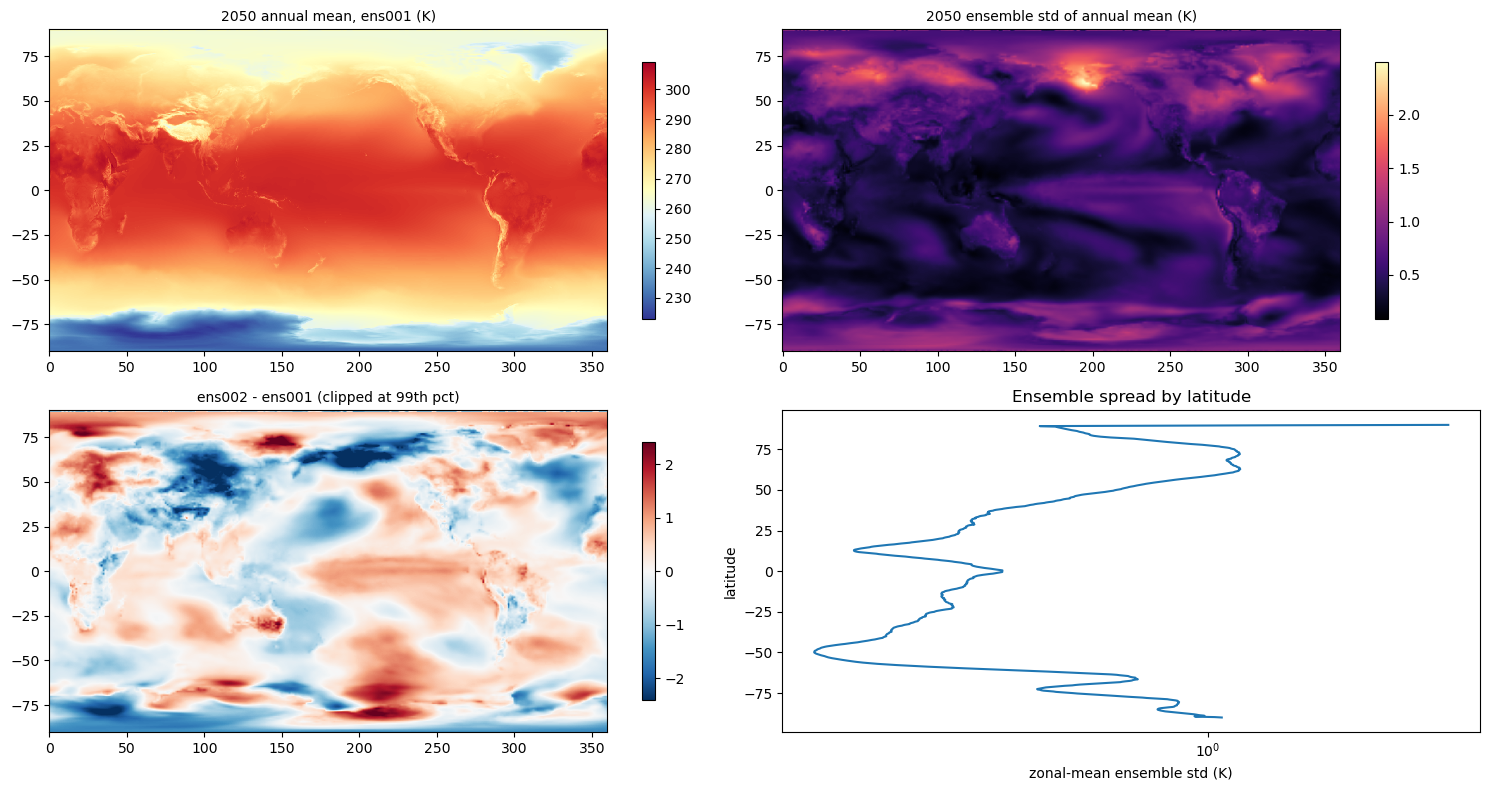

In [10]:
# Maps: member differences and ensemble spread for the first test year
y0 = years_present[0]
members = [e for e in ENSEMBLES if (e, y0) in SCANS]
stack = np.stack([SCANS[(e, y0)]["mean_map"] for e in members])
ens_std = np.nanstd(stack, axis=0)
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_map(axes[0, 0], stack[0], LAT, LON, f"{y0} annual mean, ens{members[0]:03d} (K)", cmap="RdYlBu_r")
plot_map(axes[0, 1], ens_std, LAT, LON, f"{y0} ensemble std of annual mean (K)", cmap="magma")
dm = stack[1] - stack[0]
lim = np.nanpercentile(np.abs(dm), 99)
plot_map(axes[1, 0], dm, LAT, LON, f"ens{members[1]:03d} - ens{members[0]:03d} (clipped at 99th pct)", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1, 1].plot(np.nanmean(ens_std, axis=1), LAT)
axes[1, 1].set(xlabel="zonal-mean ensemble std (K)", ylabel="latitude", title="Ensemble spread by latitude")
axes[1, 1].set_xscale("symlog", linthresh=1e-3)
plt.tight_layout(); plt.show()

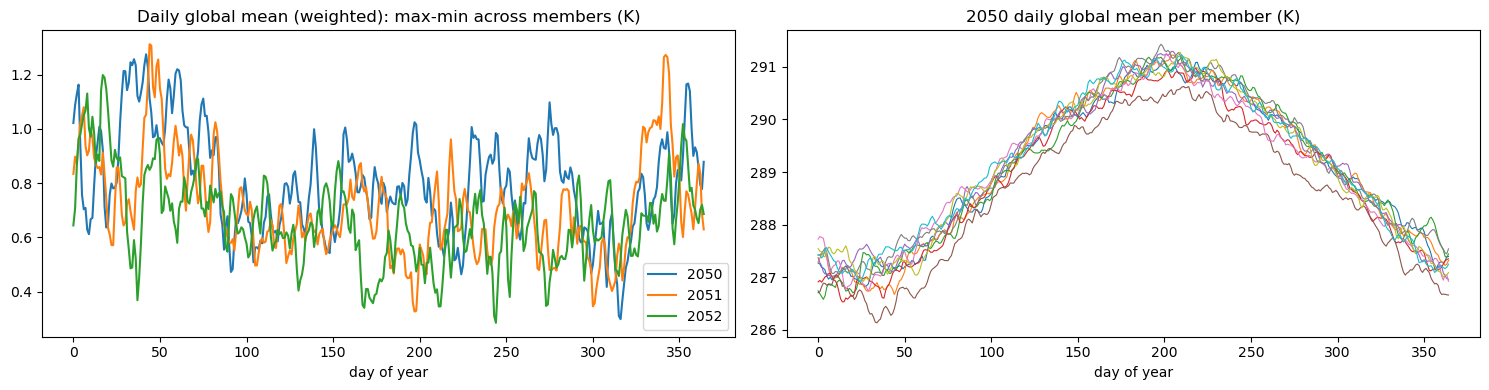

max daily spread of global mean across members, all test years: 1.434e+00 K


In [11]:
# Daily global mean: does the ensemble differ day-to-day even though the annual mean agrees?
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for y in years_present[:3]:
    ms = [e for e in ENSEMBLES if (e, y) in SCANS]
    G = stack_trunc([SCANS[(e, y)]["gm_w"] for e in ms])
    axes[0].plot(G.max(0) - G.min(0), label=str(y))
axes[0].set(title="Daily global mean (weighted): max-min across members (K)", xlabel="day of year"); axes[0].legend()
y = years_present[0]
for e in ENSEMBLES:
    if (e, y) in SCANS:
        axes[1].plot(SCANS[(e, y)]["gm_w"], lw=0.8, label=f"ens{e:03d}")
axes[1].set(title=f"{y} daily global mean per member (K)", xlabel="day of year")
plt.tight_layout(); plt.show()
dd = 0.0
for y in years_present:
    G = stack_trunc([SCANS[(e, y)]["gm_w"] for e in ENSEMBLES if (e, y) in SCANS])
    dd = max(dd, float(np.nanmax(G.max(0) - G.min(0))))
print(f"max daily spread of global mean across members, all test years: {dd:.3e} K")
if dd < 1e-6:
    flag("daily global means are identical across members too (not just annual): the global-mean time series is shared")

In [12]:
# Is the spatial texture shared between members? (correlation of annual-mean anomalies from zonal mean)
rows = []
for y in years_present:
    ms = [e for e in ENSEMBLES if (e, y) in SCANS]
    anoms = {}
    for e in ms:
        m = SCANS[(e, y)]["mean_map"]
        anoms[e] = (m - np.nanmean(m, axis=1, keepdims=True)).ravel()
    ref = anoms[ms[0]]
    for e in ms[1:]:
        ok_ = np.isfinite(ref) & np.isfinite(anoms[e])
        rows.append(dict(year=y, ens=e, corr_with_ens1=np.corrcoef(ref[ok_], anoms[e][ok_])[0, 1]))
corr = pd.DataFrame(rows)
display(corr.pivot(index="year", columns="ens", values="corr_with_ens1").round(4))
print("Values near 1 => members share the same fine-scale spatial pattern; near 0 => independent patterns.")

ens,2,3,4,5,6,7,8,9,10
year,,,,,,,,,
2050,0.9899,0.9827,0.9879,0.9912,0.9828,0.9903,0.9784,0.9771,0.9848
2051,0.9846,0.9898,0.9855,0.9898,0.9837,0.9876,0.9883,0.9876,0.9867
2052,0.9883,0.9794,0.9772,0.9863,0.9711,0.9864,0.9884,0.9808,0.9789
2053,0.9816,0.9847,0.9842,0.9848,0.9865,0.9854,0.9884,0.9838,0.9797
2054,0.9770,0.9874,0.9862,0.9868,0.9881,0.9836,0.9809,0.9845,0.9883
2055,0.9821,0.9864,0.9884,0.9868,0.9841,0.9883,0.9851,0.9887,0.9881


Values near 1 => members share the same fine-scale spatial pattern; near 0 => independent patterns.


## 6. Polar bug analysis

* Per-latitude min / max over every scanned file, against the plausible range.
* Map of outlier counts, aggregated over all files.
* Per-latitude outlier rate, and the latitude at which outliers begin.
* Worst individual grid cells.
* Whether the same cells are bad in every member (Jaccard overlap) - same cells everywhere points to the shared correction/downscaling step rather than member-specific data.
* Behaviour of the first / last latitude row (pole rows).

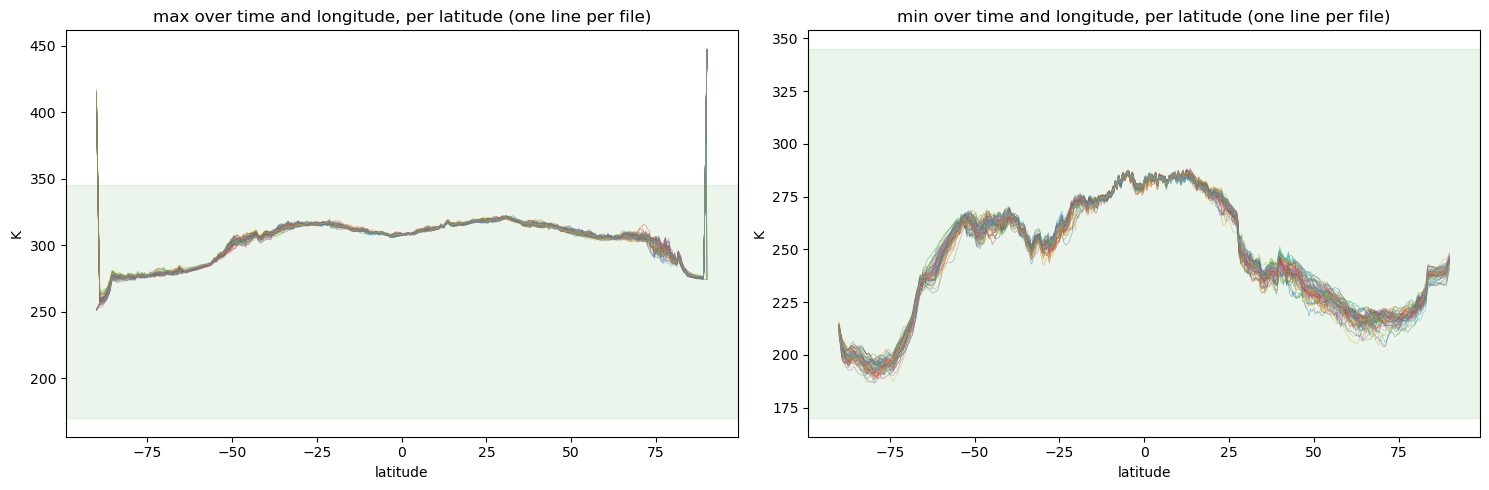

total outlier gridpoint-days: 1486831
FLAG: 1486831 gridpoint-days outside (170.0, 345.0) K across scanned files


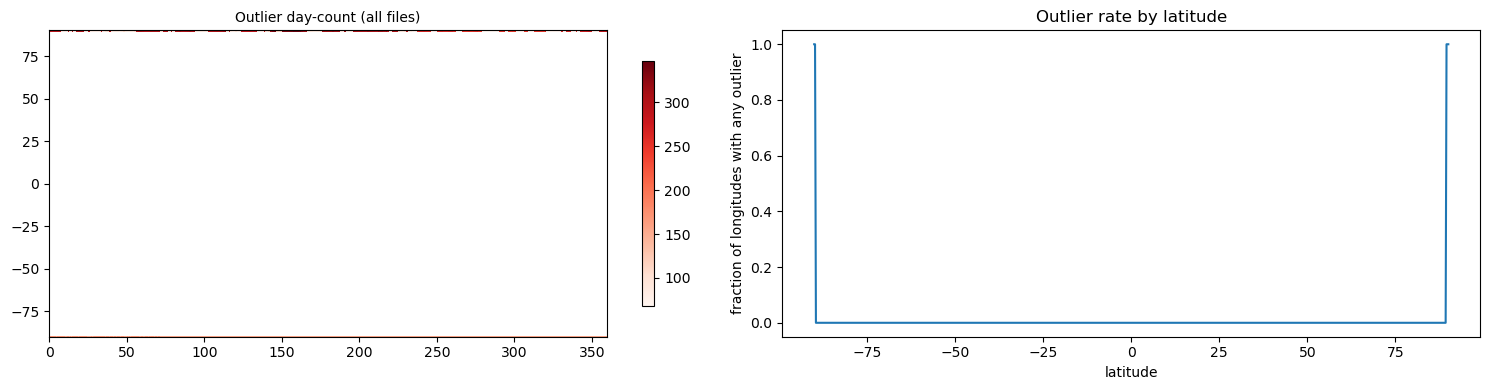

outliers occur at latitudes between -90.00 and 90.00
smallest |lat| with outliers:  89.5
outlier lats > 0: 3  < 0: 2


In [13]:
keys = sorted(SCANS)
mins = np.stack([np.nanmin(SCANS[k]["min_map"], axis=1) for k in keys])   # (files, lat)
maxs = np.stack([np.nanmax(SCANS[k]["max_map"], axis=1) for k in keys])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, arr, nm in [(axes[0], maxs, "max"), (axes[1], mins, "min")]:
    ax.plot(LAT, arr.T, lw=0.5, alpha=0.5)
    ax.axhspan(*PLAUSIBLE_K, color="green", alpha=0.08)
    ax.set(xlabel="latitude", ylabel="K", title=f"{nm} over time and longitude, per latitude (one line per file)")
plt.tight_layout(); plt.show()

out_total = sum(S["out_hi"].astype(np.int64) + S["out_lo"].astype(np.int64) for S in SCANS.values())
print("total outlier gridpoint-days:", int(out_total.sum()))
if out_total.sum() > 0:
    flag(f"{int(out_total.sum())} gridpoint-days outside {PLAUSIBLE_K} K across scanned files")
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    plot_map(axes[0], np.where(out_total > 0, out_total, np.nan), LAT, LON, "Outlier day-count (all files)", cmap="Reds")
    rate = (out_total > 0).mean(axis=1)
    axes[1].plot(LAT, rate); axes[1].set(xlabel="latitude", ylabel="fraction of longitudes with any outlier", title="Outlier rate by latitude")
    plt.tight_layout(); plt.show()
    bad_lats = LAT[rate > 0]
    print(f"outliers occur at latitudes between {bad_lats.min():.2f} and {bad_lats.max():.2f}")
    print("smallest |lat| with outliers: ", np.abs(bad_lats).min())
    print("outlier lats > 0:", (bad_lats > 0).sum(), " < 0:", (bad_lats < 0).sum())

In [14]:
# Worst individual grid cells (largest excursion beyond the plausible range)
recs = []
for k in keys:
    S = SCANS[k]
    for nm, arr, fn in [("max", S["max_map"], np.nanargmax), ("min", S["min_map"], np.nanargmin)]:
        i = np.unravel_index(fn(arr), arr.shape)
        v = float(arr[i])
        excess = max(v - PLAUSIBLE_K[1], PLAUSIBLE_K[0] - v)
        recs.append(dict(ens=k[0], year=k[1], kind=nm, lat=LAT[i[0]], lon=LON[i[1]], value_K=v, excess=excess))
worst = pd.DataFrame(recs).sort_values("excess", ascending=False)
display(worst.head(20))
display(worst.groupby("kind")[["value_K"]].describe())

,ens,year,kind,lat,lon,value_K,excess
52,5,2052,max,90.0,0.0,447.589142,102.589142
116,10,2054,max,90.0,0.0,447.546265,102.546265
118,10,2055,max,90.0,0.0,447.334229,102.334229
104,9,2054,max,90.0,0.0,447.322693,102.322693
106,9,2055,max,90.0,0.0,447.222321,102.222321
0,1,2050,max,90.0,0.0,447.139252,102.139252
18,2,2053,max,90.0,0.0,447.123840,102.123840
12,2,2050,max,90.0,0.0,447.096313,102.096313
74,7,2051,max,90.0,0.0,447.079163,102.079163
44,4,2054,max,90.0,0.0,447.020782,102.020782


value_K                                                                                   
       count        mean        std         min         25%         50%         75%         max
kind                                                                                           
max     60.0  443.451811  10.401314  411.120422  446.742653  446.829666  446.931946  447.589142
min     60.0  192.223498   2.667265  186.677429  190.201447  192.483360  194.454464  198.479767

In [15]:
# Do different members share the same bad cells?
y = years_present[0]
ms = [e for e in ENSEMBLES if (e, y) in SCANS]
masks = {e: (SCANS[(e, y)]["out_hi"] + SCANS[(e, y)]["out_lo"]) > 0 for e in ms}
J = pd.DataFrame(index=ms, columns=ms, dtype=float)
for a, b in itertools.product(ms, ms):
    u = (masks[a] | masks[b]).sum()
    J.loc[a, b] = (masks[a] & masks[b]).sum() / u if u else np.nan
print(f"Jaccard overlap of outlier-cell sets, year {y} (nan = no outliers):")
display(J.round(3))
print("n outlier cells per member:", {e: int(masks[e].sum()) for e in ms})

Jaccard overlap of outlier-cell sets, year 2050 (nan = no outliers):


,1,2,3,4,5,6,7,8,9,10
1,1.000,0.600,0.441,0.898,0.572,0.471,0.966,0.593,0.986,0.568
2,0.600,1.000,0.041,0.498,0.953,0.786,0.566,0.988,0.586,0.946
3,0.441,0.041,1.000,0.491,0.042,0.047,0.456,0.041,0.445,0.042
4,0.898,0.498,0.491,1.000,0.506,0.499,0.930,0.491,0.890,0.496
5,0.572,0.953,0.042,0.506,1.000,0.825,0.564,0.941,0.569,0.939
6,0.471,0.786,0.047,0.499,0.825,1.000,0.464,0.795,0.468,0.830
7,0.966,0.566,0.456,0.930,0.564,0.464,1.000,0.559,0.952,0.537
8,0.593,0.988,0.041,0.491,0.941,0.795,0.559,1.000,0.579,0.934
9,0.986,0.586,0.445,0.890,0.569,0.468,0.952,0.579,1.000,0.565
10,0.568,0.946,0.042,0.496,0.939,0.830,0.537,0.934,0.565,1.000


n outlier cells per member: {1: 7200, 2: 4320, 3: 3174, 4: 6468, 5: 4116, 6: 3394, 7: 6954, 8: 4268, 9: 7098, 10: 4088}


lat        row_mean        row_std_over_lon      row_min        row_max       
                min    max      min    max              min  max     min    max     min    max
row                                                                                           
2nd_last_row  89.75  89.75   262.18 266.58             0.06 1.49  261.85 264.39  262.85 268.45
2nd_row      -89.75 -89.75   228.43 234.96             0.25 0.42  228.01 234.51  228.89 235.58
first_row    -90.00 -90.00   228.66 236.66             0.00 0.30  228.64 236.61  228.67 237.08
last_row      90.00  90.00   262.02 269.62             0.00 0.00  262.02 269.62  262.02 269.62

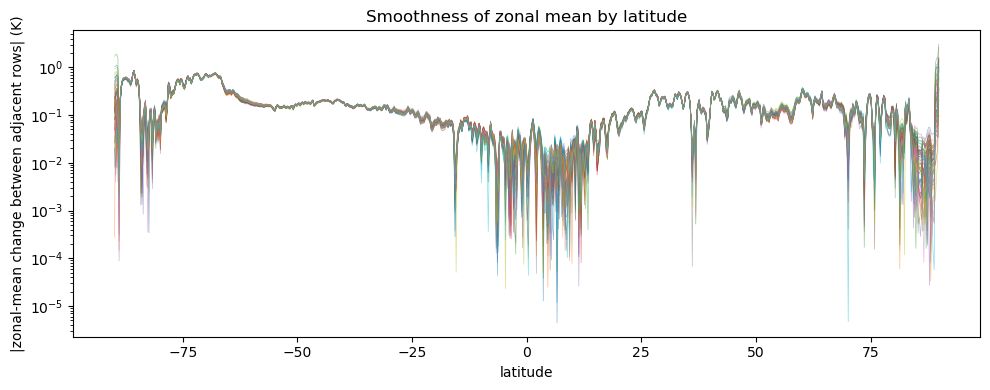

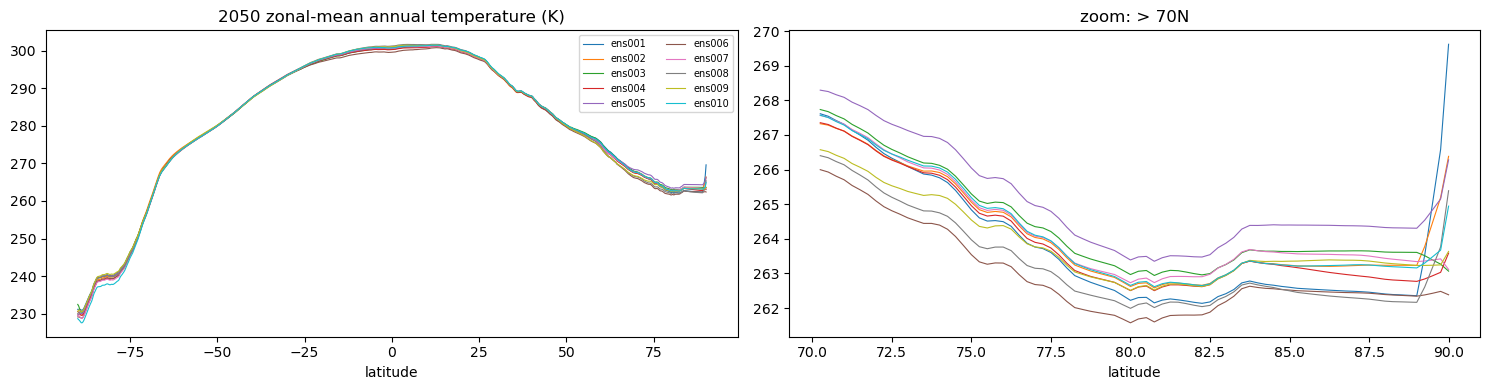

In [16]:
# Pole rows: annual-mean value at the first / last latitude row and how much it varies along longitude
rows = []
for k in keys:
    m = SCANS[k]["mean_map"]
    for nm, idx in [("first_row", 0), ("last_row", -1), ("2nd_row", 1), ("2nd_last_row", -2)]:
        rows.append(dict(ens=k[0], year=k[1], row=nm, lat=LAT[idx], row_mean=np.nanmean(m[idx]),
                         row_std_over_lon=np.nanstd(m[idx]), row_min=np.nanmin(m[idx]), row_max=np.nanmax(m[idx])))
pole = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(pole.groupby("row")[["lat", "row_mean", "row_std_over_lon", "row_min", "row_max"]].agg(["min", "max"]))

# Row-to-row jump in zonal-mean annual temperature (a smooth field has small jumps)
zm = np.stack([np.nanmean(SCANS[k]["mean_map"], axis=1) for k in keys])
jump = np.abs(np.diff(zm, axis=1))
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(0.5 * (LAT[1:] + LAT[:-1]), jump.T, lw=0.5, alpha=0.5)
ax.set(xlabel="latitude", ylabel="|zonal-mean change between adjacent rows| (K)", title="Smoothness of zonal mean by latitude")
plt.tight_layout(); plt.show()

# Compare polar bands across members: zonal mean profile, ensemble mean +- range
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
y = years_present[0]
for e in [e for e in ENSEMBLES if (e, y) in SCANS]:
    zmm = np.nanmean(SCANS[(e, y)]["mean_map"], axis=1)
    axes[0].plot(LAT, zmm, lw=0.8, label=f"ens{e:03d}")
    axes[1].plot(LAT[LAT > 70], zmm[LAT > 70], lw=0.8)
axes[0].set(title=f"{y} zonal-mean annual temperature (K)", xlabel="latitude"); axes[0].legend(ncol=2, fontsize=7)
axes[1].set(title="zoom: > 70N", xlabel="latitude")
plt.tight_layout(); plt.show()

## 7. Temporal checks and ensemble independence

* Day-to-day jumps in the global-mean series and continuity across the 31 Dec -> 1 Jan boundary between consecutive years.
* Time series at selected grid points (equator, mid-latitude, high latitude, both poles) for all members: how large is the ensemble spread, and are the members' day-to-day anomalies correlated? A real ensemble has independent weather (correlation near 0 after removing the seasonal cycle); correlation near 1 means members share their daily variability.

In [17]:
# Day-to-day jumps in global mean and year-boundary continuity
rows = []
for e in ENSEMBLES:
    ys = [y for y in years_present if (e, y) in SCANS]
    allgm = np.concatenate([SCANS[(e, y)]["gm_w"] for y in ys]) if ys else np.array([])
    if len(allgm) < 3: continue
    d = np.diff(allgm); s = np.nanstd(d)
    bounds = []
    off = 0
    for y in ys[:-1]:
        off += len(SCANS[(e, y)]["gm_w"]); bounds.append(abs(allgm[off] - allgm[off - 1]))
    rows.append(dict(ens=e, std_daily_change=s, max_daily_change=np.nanmax(np.abs(d)),
                     n_days_gt_5sigma=int((np.abs(d) > 5 * s).sum()),
                     max_year_boundary_jump=max(bounds) if bounds else np.nan,
                     boundary_over_sigma=(max(bounds) / s) if bounds else np.nan))
tj = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tj)
if len(tj) and (tj.boundary_over_sigma > 5).any():
    flag("a year-boundary jump in global mean exceeds 5x typical day-to-day change: check continuity between files")

,ens,std_daily_change,max_daily_change,n_days_gt_5sigma,max_year_boundary_jump,boundary_over_sigma
0,1,0.0579,0.2064,0,0.0803,1.3888
1,2,0.0573,0.2366,0,0.0715,1.2469
2,3,0.0570,0.2474,0,0.1438,2.5222
3,4,0.0555,0.2247,0,0.0481,0.8674
4,5,0.0565,0.1812,0,0.0773,1.3686
5,6,0.0576,0.2296,0,0.1011,1.7566
6,7,0.0576,0.2175,0,0.0946,1.6419
7,8,0.0564,0.2020,0,0.1092,1.9364
8,9,0.0563,0.2573,0,0.1080,1.9184
9,10,0.0559,0.1829,0,0.0723,1.2949


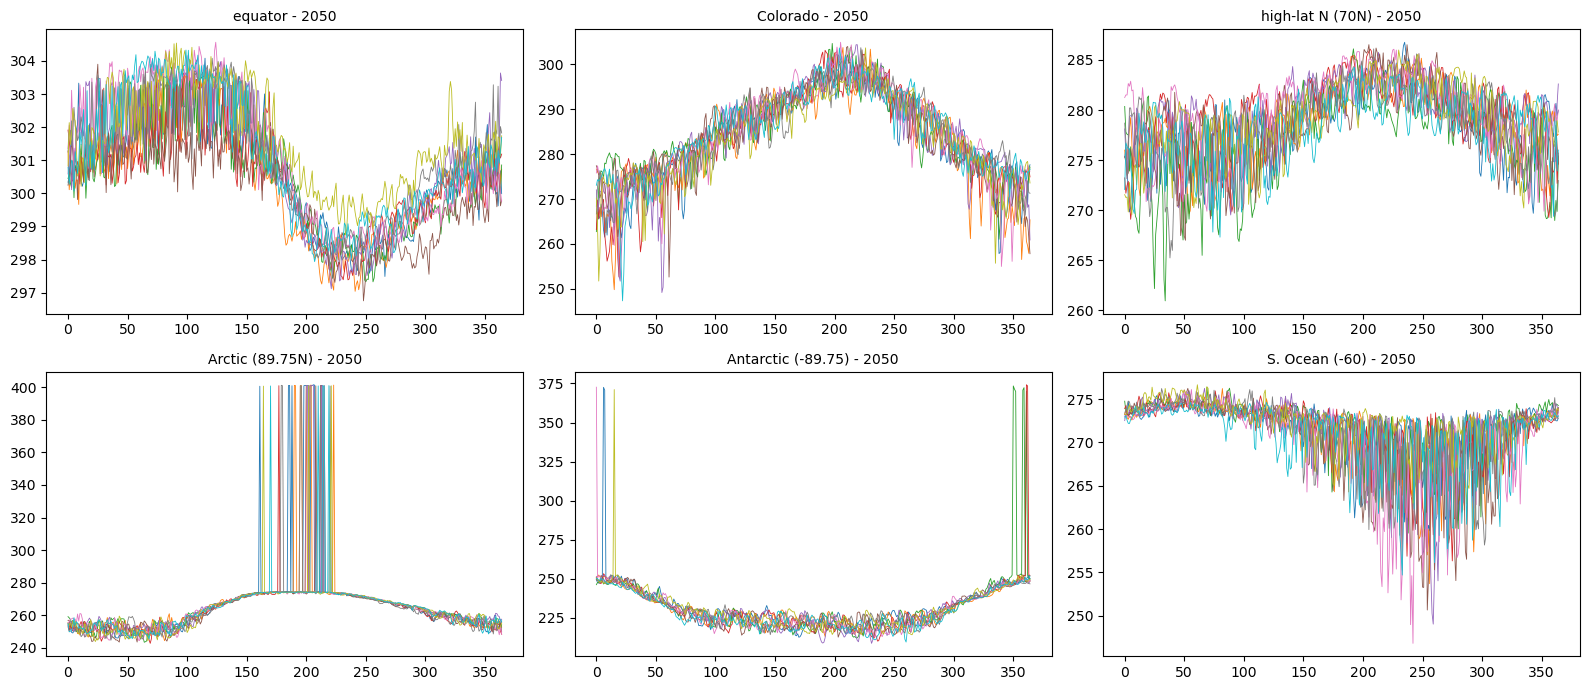

,point,ens_std_mean,ens_range_max,min_K,max_K,mean_offdiag_anomaly_corr
0,equator,0.742,4.173,296.754,304.563,-0.002
1,Colorado,3.310,30.822,247.345,304.885,0.007
2,high-lat N (70N),2.455,20.139,260.948,286.765,-0.025
3,Arctic (89.75N),5.570,128.828,242.633,401.635,0.001
4,Antarctic (-89.75),3.980,127.526,208.720,374.175,0.011
5,S. Ocean (-60),2.199,25.947,246.818,276.656,0.017


In [18]:
# Point time series for all members (first test year)
y = years_present[0]
POINTS = {"equator": (0, 0), "Colorado": (40.6, 255.0), "high-lat N (70N)": (70, 0),
          "Arctic (89.75N)": (89.75, 0), "Antarctic (-89.75)": (-89.75, 0), "S. Ocean (-60)": (-60, 0)}
def sample_points(ens, year):
    ds = open_member(ens, year); da = get_var(ds); latn, lonn = coord_names(da)
    out = {}
    neg = float(ds[lonn].min()) < 0
    for nm, (la, lo) in POINTS.items():
        lo2 = ((lo + 180) % 360) - 180 if neg else lo % 360
        out[nm] = da.sel({latn: la, lonn: lo2}, method="nearest").values.astype(float)
    ds.close()
    return out

pts = {e: sample_points(e, y) for e in ENSEMBLES if os.path.exists(fpath(e, y))}
rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 7)); axes = axes.ravel()
for ax, nm in zip(axes, POINTS):
    M = stack_trunc([pts[e][nm] for e in pts])                           # (members, time)
    for i, e in enumerate(pts): ax.plot(M[i], lw=0.6)
    ax.set_title(f"{nm} - {y}", fontsize=10)
    anom = pd.DataFrame(M.T) - pd.DataFrame(M.T).rolling(31, center=True, min_periods=1).mean()
    C = anom.corr().values
    off = C[~np.eye(len(C), dtype=bool)]
    rows.append(dict(point=nm, ens_std_mean=M.std(0).mean(), ens_range_max=(M.max(0) - M.min(0)).max(),
                     min_K=M.min(), max_K=M.max(), mean_offdiag_anomaly_corr=np.nanmean(off)))
plt.tight_layout(); plt.show()
pt = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pt)
if (pt.mean_offdiag_anomaly_corr > 0.9).any():
    flag("members' daily anomalies are highly correlated at some points (shared day-to-day variability)")

## 8. Summary of flags

In [19]:
print(f"{len(FLAGS)} flag(s) raised:\n")
for i, f in enumerate(FLAGS, 1):
    print(f"{i:2d}. {f}")

# Save tables for sharing / reuse
for nm, df in [("inventory", inv), ("coords", coords), ("diff_tests", diffres), ("file_summary", ann),
               ("pairwise_spatial", pw), ("worst_cells", worst), ("point_stats", pt)]:
    try: df.to_csv(os.path.join(CACHE_DIR, f"{nm}.csv"), index=False)
    except Exception as e: print("could not save", nm, e)
print("\nCSV tables written to", CACHE_DIR)

3 flag(s) raised:

 1. 50 difference operations silently returned EMPTY arrays (coordinate misalignment, typically year-vs-year because time labels differ)
 2. values outside (170.0, 345.0) K in 60 files
 3. 1486831 gridpoint-days outside (170.0, 345.0) K across scanned files

CSV tables written to ./scan_cache
